In [2]:
from pathlib import Path
import itertools
import os
import pandas as pd

In [3]:
machines = ["M01","M02","M03"]
process_names = [
    "OP00", "OP01", "OP02", "OP03", "OP04",
    "OP05", "OP06", "OP07", "OP08", "OP09",
    "OP10", "OP11", "OP12", "OP13", "OP14"
]

labels = ["good", "bad"]

path_to_dataset = Path("../data/raw/").absolute()

print("Dataset path:", path_to_dataset)
print("Exists:", path_to_dataset.exists())

Dataset path: c:\Users\T9943\project-1\notebooks\..\data\raw
Exists: True


In [4]:
X_data = []
y_data = []

for process_name, machine, label in itertools.product(
    process_names, machines, labels
):
    data_path = os.path.join(
        path_to_dataset,
        machine,
        process_name,
        label
    )

    if not os.path.exists(data_path):
        continue

    for file in os.listdir(data_path):
        if file.endswith(".csv"):
            file_path = os.path.join(data_path, file)

            df = pd.read_csv(file_path)

            X_data.append(df)
            y_data.append(label)

In [5]:
print("Number of CSV files:", len(X_data))
print("Number of labels:", len(y_data))

Number of CSV files: 1702
Number of labels: 1702


In [6]:
X_data[0].head()

,x,y,z
0,-9.0,9.0,-1011.0
1,-21.0,19.0,-1011.0
2,-15.0,23.0,-1020.0
3,-9.0,27.0,-1013.0
4,-9.0,17.0,-1020.0


In [7]:
X_data[0].columns

Index(['x', 'y', 'z'], dtype='object')

In [8]:
X_data[0].dtypes

x    float64
y    float64
z    float64
dtype: object

In [9]:
X_data[0].isnull().sum()

x    0
y    0
z    0
dtype: int64

In [10]:
X_data[0].describe

<bound method NDFrame.describe of            x     y       z
0       -9.0   9.0 -1011.0
1      -21.0  19.0 -1011.0
2      -15.0  23.0 -1020.0
3       -9.0  27.0 -1013.0
4       -9.0  17.0 -1020.0
...      ...   ...     ...
268283 -17.0  23.0 -1013.0
268284 -19.0  19.0 -1009.0
268285 -13.0  33.0 -1015.0
268286 -13.0  27.0 -1016.0
268287 -31.0  25.0 -1020.0

[268288 rows x 3 columns]>

In [14]:
from collections import Counter
Counter(y_data)

Counter({'good': 1632, 'bad': 70})

array([[<Axes: title={'center': 'x'}>, <Axes: title={'center': 'y'}>],
       [<Axes: title={'center': 'z'}>, <Axes: >]], dtype=object)

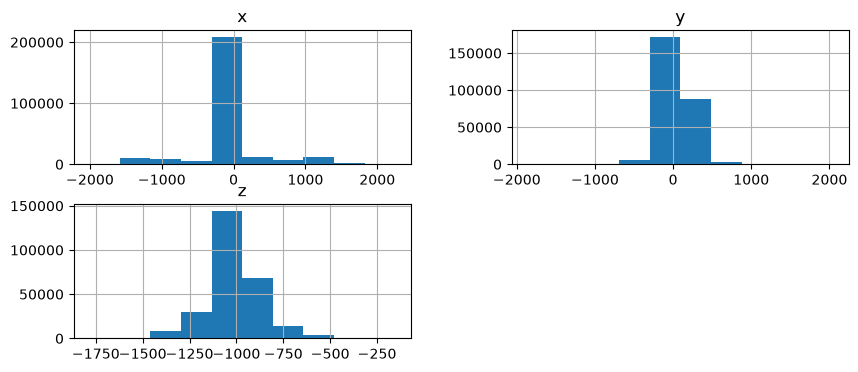

In [15]:
X_data[0].hist(figsize =(10,4))

In [16]:
shapes = [df.shape for df in X_data]

print("Unique shapes:", set(shapes))

Unique shapes: {(94208, 3), (117760, 3), (81920, 3), (263168, 3), (50000, 3), (120000, 3), (203904, 3), (44000, 3), (93600, 3), (133120, 3), (86000, 3), (264000, 3), (72000, 3), (184320, 3), (64231, 3), (84992, 3), (59184, 3), (97280, 3), (120832, 3), (211968, 3), (89088, 3), (176128, 3), (188400, 3), (46000, 3), (76800, 3), (112640, 3), (162000, 3), (100352, 3), (30191, 3), (135600, 3), (191488, 3), (103781, 3), (128000, 3), (215040, 3), (92160, 3), (179200, 3), (86400, 3), (115712, 3), (79872, 3), (214144, 3), (75741, 3), (206848, 3), (88000, 3), (131072, 3), (44032, 3), (95232, 3), (218112, 3), (62500, 3), (124731, 3), (186368, 3), (209920, 3), (114006, 3), (213600, 3), (134144, 3), (107161, 3), (139653, 3), (208784, 3), (201728, 3), (138240, 3), (49248, 3), (189440, 3), (138000, 3), (125952, 3), (212992, 3), (217088, 3), (32199, 3), (204800, 3), (141312, 3), (66848, 3), (36000, 3), (129024, 3), (38912, 3), (220160, 3), (206904, 3), (180000, 3), (207872, 3), (102400, 3), (54272, 3),

In [17]:
all_data = pd.concat(X_data, ignore_index=True)

all_data.describe()

,x,y,z
count,1.786012e+08,1.786012e+08,1.786012e+08
mean,3.068029e+00,1.753622e+01,-1.024491e+03
std,3.996460e+02,2.048679e+02,2.034133e+02
min,-9.234000e+03,-6.552000e+03,-4.753000e+03
25%,-5.600000e+01,-7.400000e+01,-1.116000e+03
50%,5.000000e+00,1.700000e+01,-1.024000e+03
75%,6.200000e+01,1.090000e+02,-9.330000e+02
max,8.657000e+03,6.023000e+03,3.090000e+03


In [18]:
print("X range:", all_data["x"].min(), "to", all_data["x"].max())
print("Y range:", all_data["y"].min(), "to", all_data["y"].max())
print("Z range:", all_data["z"].min(), "to", all_data["z"].max())

X range: -9234.0 to 8657.0
Y range: -6552.0 to 6023.0
Z range: -4753.0 to 3090.0


In [19]:
machine_counts = {
    machine: 0
    for machine in machines
}

for machine in machines:
    for process_name in process_names:
        for label in labels:
            data_path = path_to_dataset / machine / process_name / label

            if data_path.exists():
                machine_counts[machine] += len(list(data_path.glob("*.csv")))

machine_counts

{'M01': 519, 'M02': 644, 'M03': 539}

In [20]:
machine_label_counts = {}

for machine in machines:
    machine_label_counts[machine] = {}

    for label in labels:
        count = 0

        for process_name in process_names:
            data_path = path_to_dataset / machine / process_name / label

            if data_path.exists():
                count += len(list(data_path.glob("*.csv")))

        machine_label_counts[machine][label] = count

pd.DataFrame(machine_label_counts).T

,good,bad
M01,485,34
M02,617,27
M03,530,9


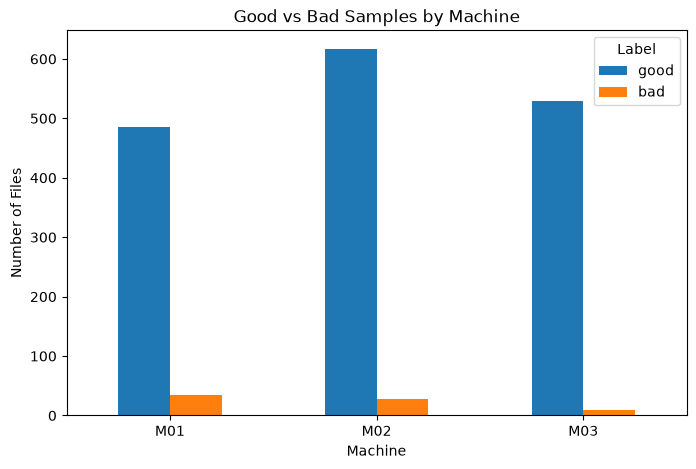

In [21]:
import matplotlib.pyplot as plt

pd.DataFrame(machine_label_counts).T.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Machine")
plt.ylabel("Number of Files")
plt.title("Good vs Bad Samples by Machine")
plt.xticks(rotation=0)
plt.legend(title="Label")
plt.show()

In [22]:
file_stats = []

for i, df in enumerate(X_data):
    stats = {
        "file_id": i,
        "label": y_data[i],

        "x_mean": df["x"].mean(),
        "x_std": df["x"].std(),
        "x_min": df["x"].min(),
        "x_max": df["x"].max(),

        "y_mean": df["y"].mean(),
        "y_std": df["y"].std(),
        "y_min": df["y"].min(),
        "y_max": df["y"].max(),

        "z_mean": df["z"].mean(),
        "z_std": df["z"].std(),
        "z_min": df["z"].min(),
        "z_max": df["z"].max(),

        "n_samples": len(df)
    }

    file_stats.append(stats)

In [23]:
stats_df = pd.DataFrame(file_stats)

stats_df.head()

,file_id,label,x_mean,x_std,x_min,x_max,y_mean,y_std,y_min,y_max,z_mean,z_std,z_min,z_max,n_samples
0,0,good,-3.874870,469.406993,-2012.0,2252.0,34.393633,158.931394,-1868.0,2051.0,-1014.514865,142.390191,-1786.0,-152.0,268288
1,1,good,-4.080831,469.337859,-1940.0,2246.0,34.439658,156.544574,-1887.0,1932.0,-1014.888903,142.393356,-1795.0,-220.0,268288
2,2,good,-4.016684,469.255959,-2260.0,2168.0,32.277508,140.611312,-1823.0,1842.0,-1014.742229,136.813576,-1672.0,-216.0,268288
3,3,good,-4.769266,470.199924,-2022.0,2324.0,32.967493,140.767209,-1879.0,2131.0,-1015.024702,142.254719,-1768.0,-279.0,264192
4,4,good,-5.025476,468.323531,-2008.0,2004.0,32.631773,143.524317,-1774.0,2039.0,-1015.094961,142.542050,-1663.0,-316.0,268288


In [24]:
stats_df.groupby("label").mean(numeric_only=True)

,file_id,x_mean,x_std,x_min,x_max,y_mean,y_std,y_min,y_max,z_mean,z_std,z_min,z_max,n_samples
label,,,,,,,,,,,,,,
bad,836.885714,6.456949,416.517732,-2147.100000,2152.828571,22.564681,275.086723,-1628.228571,1628.957143,-1035.316439,293.196166,-2274.214286,243.557143,80286.428571
good,851.083946,3.209245,393.752822,-2449.962623,2441.037377,17.152493,193.232485,-1807.401961,1843.355392,-1024.315690,190.280410,-2142.750613,28.312500,105993.376225


In [25]:
feature_data = []

for df, label in zip(X_data, y_data):

    features = {
        "x_mean": df["x"].mean(),
        "x_std": df["x"].std(),
        "x_min": df["x"].min(),
        "x_max": df["x"].max(),

        "y_mean": df["y"].mean(),
        "y_std": df["y"].std(),
        "y_min": df["y"].min(),
        "y_max": df["y"].max(),

        "z_mean": df["z"].mean(),
        "z_std": df["z"].std(),
        "z_min": df["z"].min(),
        "z_max": df["z"].max(),

        "n_samples": len(df),

        "label": label
    }

    feature_data.append(features)

In [26]:
features_df = pd.DataFrame(feature_data)

features_df.head()

,x_mean,x_std,x_min,x_max,y_mean,y_std,y_min,y_max,z_mean,z_std,z_min,z_max,n_samples,label
0,-3.874870,469.406993,-2012.0,2252.0,34.393633,158.931394,-1868.0,2051.0,-1014.514865,142.390191,-1786.0,-152.0,268288,good
1,-4.080831,469.337859,-1940.0,2246.0,34.439658,156.544574,-1887.0,1932.0,-1014.888903,142.393356,-1795.0,-220.0,268288,good
2,-4.016684,469.255959,-2260.0,2168.0,32.277508,140.611312,-1823.0,1842.0,-1014.742229,136.813576,-1672.0,-216.0,268288,good
3,-4.769266,470.199924,-2022.0,2324.0,32.967493,140.767209,-1879.0,2131.0,-1015.024702,142.254719,-1768.0,-279.0,264192,good
4,-5.025476,468.323531,-2008.0,2004.0,32.631773,143.524317,-1774.0,2039.0,-1015.094961,142.542050,-1663.0,-316.0,268288,good


In [27]:
features_df.shape

(1702, 14)

In [28]:
features_df.groupby("label").mean(numeric_only=True)

,x_mean,x_std,x_min,x_max,y_mean,y_std,y_min,y_max,z_mean,z_std,z_min,z_max,n_samples
label,,,,,,,,,,,,,
bad,6.456949,416.517732,-2147.100000,2152.828571,22.564681,275.086723,-1628.228571,1628.957143,-1035.316439,293.196166,-2274.214286,243.557143,80286.428571
good,3.209245,393.752822,-2449.962623,2441.037377,17.152493,193.232485,-1807.401961,1843.355392,-1024.315690,190.280410,-2142.750613,28.312500,105993.376225


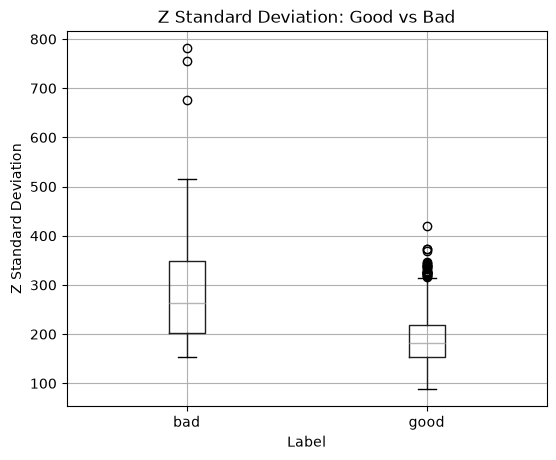

In [29]:
features_df.boxplot(column="z_std", by="label", figsize=(6, 5))

plt.title("Z Standard Deviation: Good vs Bad")
plt.suptitle("")
plt.xlabel("Label")
plt.ylabel("Z Standard Deviation")
plt.show()

In [30]:
import numpy as np

for i, df in enumerate(X_data):
    features_df.loc[i, "x_rms"] = np.sqrt(np.mean(df["x"] ** 2))
    features_df.loc[i, "y_rms"] = np.sqrt(np.mean(df["y"] ** 2))
    features_df.loc[i, "z_rms"] = np.sqrt(np.mean(df["z"] ** 2))

In [31]:
for i, df in enumerate(X_data):
    features_df.loc[i, "x_ptp"] = df["x"].max() - df["x"].min()
    features_df.loc[i, "y_ptp"] = df["y"].max() - df["y"].min()
    features_df.loc[i, "z_ptp"] = df["z"].max() - df["z"].min()

In [32]:
for i, df in enumerate(X_data):
    features_df.loc[i, "x_skew"] = df["x"].skew()
    features_df.loc[i, "y_skew"] = df["y"].skew()
    features_df.loc[i, "z_skew"] = df["z"].skew()

    features_df.loc[i, "x_kurtosis"] = df["x"].kurtosis()
    features_df.loc[i, "y_kurtosis"] = df["y"].kurtosis()
    features_df.loc[i, "z_kurtosis"] = df["z"].kurtosis()

In [33]:
features_df.head()

,x_mean,x_std,x_min,x_max,y_mean,y_std,y_min,y_max,z_mean,z_std,...,z_rms,x_ptp,y_ptp,z_ptp,x_skew,y_skew,z_skew,x_kurtosis,y_kurtosis,z_kurtosis
0,-3.874870,469.406993,-2012.0,2252.0,34.393633,158.931394,-1868.0,2051.0,-1014.514865,142.390191,...,1024.458541,4264.0,3919.0,1634.0,0.000917,0.100717,0.279302,3.768191,3.686684,1.033094
1,-4.080831,469.337859,-1940.0,2246.0,34.439658,156.544574,-1887.0,1932.0,-1014.888903,142.393356,...,1024.829390,4186.0,3819.0,1575.0,-0.001823,0.122333,0.274390,3.760337,3.863759,0.990115
2,-4.016684,469.255959,-2260.0,2168.0,32.277508,140.611312,-1823.0,1842.0,-1014.742229,136.813576,...,1023.923667,4428.0,3665.0,1456.0,-0.012085,0.155182,0.228627,3.776361,6.181609,1.045479
3,-4.769266,470.199924,-2022.0,2324.0,32.967493,140.767209,-1879.0,2131.0,-1015.024702,142.254719,...,1024.944620,4346.0,4010.0,1489.0,0.005596,0.110290,0.122898,3.705825,6.546068,0.560491
4,-5.025476,468.323531,-2008.0,2004.0,32.631773,143.524317,-1774.0,2039.0,-1015.094961,142.542050,...,1025.054116,4012.0,3813.0,1347.0,0.004672,0.121863,0.080944,3.770594,6.064566,0.502985


In [34]:
features_df.groupby("label").mean(numeric_only=True).T

label,bad,good
x_mean,6.456949,3.209245
x_std,416.517732,393.752822
x_min,-2147.100000,-2449.962623
x_max,2152.828571,2441.037377
y_mean,22.564681,17.152493
y_std,275.086723,193.232485
y_min,-1628.228571,-1807.401961
y_max,1628.957143,1843.355392
z_mean,-1035.316439,-1024.315690
z_std,293.196166,190.280410
